# Cell 1 — Environment + paths

In [1]:
%matplotlib inline

In [2]:
import sys
from pathlib import Path
from mmengine.config import Config

REPO_ROOT = Path.home() / "repos" / "mmsegmentation_ppp"
sys.path.insert(0, str(REPO_ROOT))

In [3]:

CFG_PATH = REPO_ROOT / "configs" / "mytest" / "fast_scnn_mppp_truckscenes_256x512.py"

cfg = Config.fromfile(str(CFG_PATH))

print("Loaded cfg:", CFG_PATH)
print("Dataset type:", cfg.train_dataloader.dataset.type)
print("Pipelines:", [t["type"] for t in cfg.train_dataloader.dataset.pipeline])

/home/uik04723/micromamba/envs/mmseg/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded cfg: /home/uik04723/repos/mmsegmentation_ppp/configs/mytest/fast_scnn_mppp_truckscenes_256x512.py
Dataset type: TruckScenesPPPHeatmapDataset
Pipelines: ['LoadTruckScenesSample', 'BuildTruckScenesPPPHeatmap', 'TruckScenesPackSegInputs']


# Cell 2 — Import mmseg / mmengine + load config

In [4]:
# These should import without errors if custom_imports + sys.path are correct
import mmseg  # noqa

# Dataset + transforms modules you added
import mmseg.datasets.truckscenes_ppp_heatmap_dataset  # noqa
import mmseg.datasets.transforms.truckscenes_ppp_transforms  # noqa

print("Imports OK.")

Imports OK.


# Cell 3 — Sanity check custom imports (fail fast)

In [5]:
from pathlib import Path

# pick something local & writable
cfg.work_dir = str(Path.home() / "work_dirs" / "ppp_mark_truckscenes_notebook")
print("Using work_dir:", cfg.work_dir)

Using work_dir: /home/uik04723/work_dirs/ppp_mark_truckscenes_notebook


In [6]:
# import sys, subprocess
# subprocess.check_call([sys.executable, "-m", "pip", "install", "--force-reinstall", "--no-cache-dir", "setuptools==68.2.2"])

In [7]:
from pathlib import Path

# local workdir (avoid /p)
cfg.work_dir = str(Path.home() / "work_dirs" / "ppp_mark_truckscenes_notebook")

# disable tensorboard backend (unless installed)
cfg.visualizer.vis_backends = [dict(type='LocalVisBackend')]

# IMPORTANT: no multiprocessing while debugging transforms
cfg.train_dataloader.num_workers = 0
cfg.val_dataloader.num_workers = 0
cfg.train_dataloader.persistent_workers = False
cfg.val_dataloader.persistent_workers = False

In [8]:
import mmseg.datasets.transforms.truckscenes_ppp_transforms as t
[x for x in dir(t) if "Truck" in x or "Pack" in x]

['BuildTruckScenesPPPHeatmap',
 'LoadTruckScenesSample',
 'TruckScenes',
 'TruckScenesPackSegInputs']

In [9]:
from mmengine.runner import Runner
from mmengine.registry import init_default_scope

init_default_scope("mmseg")
runner = Runner.from_cfg(cfg)

train_loader = runner.train_dataloader
batch = next(iter(train_loader))
batch.keys()

03/03 11:59:31 - mmengine - INFO - 
------------------------------------------------------------
System environment:
    sys.platform: linux
    Python: 3.10.13 | packaged by conda-forge | (main, Oct 26 2023, 18:07:37) [GCC 12.3.0]
    CUDA available: True
    MUSA available: False
    numpy_random_seed: 414550862
    GPU 0: NVIDIA T1200 Laptop GPU
    CUDA_HOME: None
    GCC: gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
    PyTorch: 2.1.2+cu121
    PyTorch compiling details: PyTorch built with:
  - GCC 9.3
  - C++ Version: 201703
  - Intel(R) oneAPI Math Kernel Library Version 2022.2-Product Build 20220804 for Intel(R) 64 architecture applications
  - Intel(R) MKL-DNN v3.1.1 (Git Hash 64f6bcbcbab628e96f33a62c3e975f8535a7bde4)
  - OpenMP 201511 (a.k.a. OpenMP 4.5)
  - LAPACK is enabled (usually provided by MKL)
  - NNPACK is enabled
  - CPU capability usage: AVX512
  - CUDA Runtime 12.1
  - NVCC architecture flags: -gencode;arch=compute_50,code=sm_50;-gencode;arch=compute_60,code=sm_60;

/home/uik04723/repos/mmsegmentation_ppp/mmseg/models/losses/cross_entropy_loss.py:250: UserWarning: Default ``avg_non_ignore`` is False, if you would like to ignore the certain label and average loss over non-ignore labels, which is the same with PyTorch official cross_entropy, set ``avg_non_ignore=True``.
  warnings.warn(
/home/uik04723/repos/mmsegmentation_ppp/mmseg/engine/hooks/visualization_hook.py:60: UserWarning: The draw is False, it means that the hook for visualization will not take effect. The results will NOT be visualized or stored.
  warnings.warn('The draw is False, it means that the '
/home/uik04723/micromamba/envs/mmseg/lib/python3.10/site-packages/truckscenes/truckscenes.py:95: UserWarning: The visualization dependencies are not installed on your system! Run 'pip install "truckscenes-devkit[all]"'.
  warnings.warn('''The visualization dependencies are not installed on your system! '''


dict_keys(['inputs', 'data_samples'])

# Cell 4 — Build dataset + dataloader

In [10]:
for i, batch in enumerate(train_loader):
    if i == 0:   # ← hier Batch-Index ändern
        break

print("Gewählter Batch:", i)

# Expected: dict(inputs=<tensor>, data_samples=<list[SegDataSample]> or <SegDataSample> batched)
print("Batch keys:", batch.keys())
print("inputs:", type(batch["inputs"]), getattr(batch["inputs"], "shape", None))

ds = batch["data_samples"]
print("data_samples type:", type(ds))

# mmengine usually returns a list of SegDataSample objects for a batch
if isinstance(ds, (list, tuple)):
    print("len(data_samples):", len(ds))
    s0 = ds[0]
else:
    s0 = ds

print("Sample metainfo keys:", list(s0.metainfo.keys()))
print("gt_sem_seg:", s0.gt_sem_seg.data.shape, s0.gt_sem_seg.data.dtype)

Gewählter Batch: 0
Batch keys: dict_keys(['inputs', 'data_samples'])
inputs: <class 'list'> None
data_samples type: <class 'list'>
len(data_samples): 16
Sample metainfo keys: ['frame_idx', 'sample_token', 'img_shape', 'cam_channel', 'radar_channel', 'ori_shape']
gt_sem_seg: torch.Size([3, 943, 1980]) torch.float32


# Cell 5 — Pull one batch and inspect structure

In [15]:
gt = s0.gt_sem_seg.data  # tensor
print(np.shape(gt))

# Falls shape (1, H, W)
if gt.ndim == 3 and gt.shape[0] == 1:
    radar_mask = gt[0]
else:
    radar_mask = gt

radar_count = (radar_mask > 0).sum().item()

print("Radar point count:", radar_count)

torch.Size([3, 943, 1980])
Radar point count: 12651


In [12]:
import torch

gt = s0.gt_sem_seg.data  # [3,H,W]
I = gt[0]
D = gt[1]
V = gt[2]

# 1) intensity must be {0,1}
uniq = torch.unique(I)
print("unique intensity values:", uniq.tolist())
assert torch.all((uniq == 0) | (uniq == 1)), f"Intensity not binary, got {uniq}"

# 2) depth/vel must be 0 wherever intensity is 0
assert torch.all(D[I == 0] == 0), "Depth has nonzero values outside intensity mask"
assert torch.all(V[I == 0] == 0), "Velocity has nonzero values outside intensity mask"

print("count intensity==1:", int((I == 1).sum().item()))

unique intensity values: [0.0, 1.0]
count intensity==1: 5372


# Cell 6 — Basic correctness asserts (binary intensity + zeros outside mask)

In [13]:
%matplotlib inline

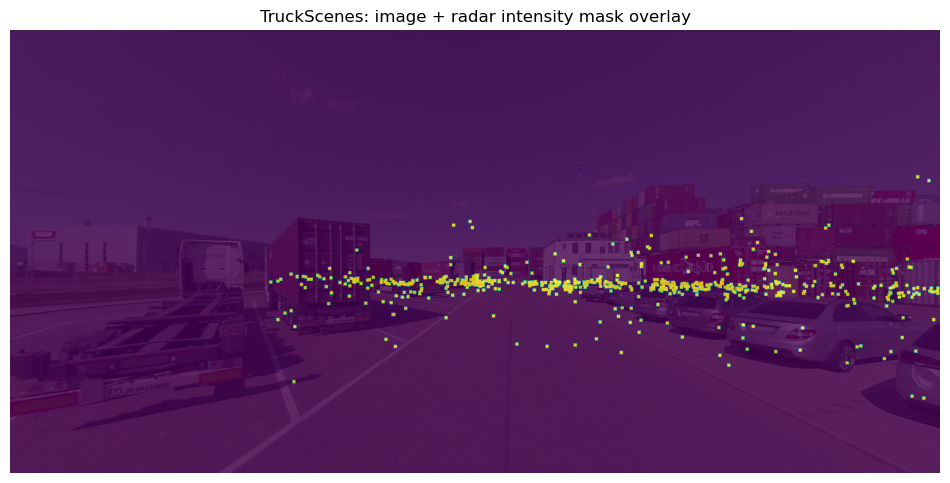

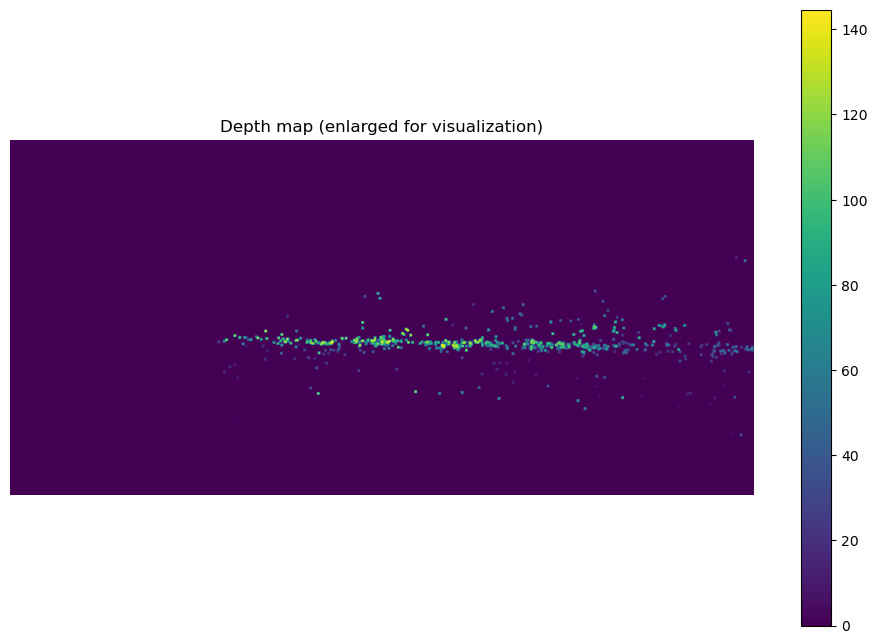

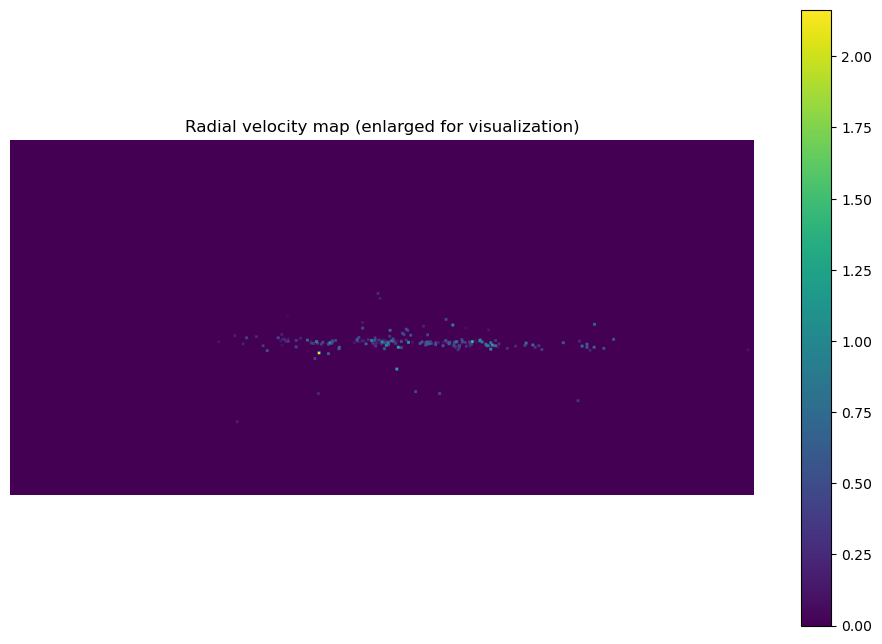

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

img = batch["inputs"][0].detach().cpu().float()  # [3,H,W]
img = img.permute(1,2,0).numpy()                 # [H,W,3]

img_vis = np.clip(img / 255.0, 0, 1)

I = s0.gt_sem_seg.data[0].detach().cpu().numpy()  # [H,W]
D = s0.gt_sem_seg.data[1].detach().cpu().numpy()
V = s0.gt_sem_seg.data[2].detach().cpu().numpy()

# ---- enlarge dots consistently ----
kernel = np.ones((5, 5), np.uint8)

I_big = cv2.dilate(I.astype(np.uint8), kernel, iterations=1)

# for depth and velocity, only dilate where mask exists
D_big = cv2.dilate(D, kernel, iterations=1)
V_big = cv2.dilate(V, kernel, iterations=1)

# ---- Plot 1: image + mask ----
plt.figure(figsize=(12, 8))
plt.imshow(img_vis)
plt.imshow(I_big, alpha=0.8)
plt.title("TruckScenes: image + radar intensity mask overlay")
plt.axis("off")
plt.show()

# ---- Plot 2: depth ----
plt.figure(figsize=(12, 8))
plt.imshow(D_big)
plt.title("Depth map (enlarged for visualization)")
plt.axis("off")
plt.colorbar()
plt.show()

# ---- Plot 3: radial velocity ----
plt.figure(figsize=(12, 8))
plt.imshow(V_big)
plt.title("Radial velocity map (enlarged for visualization)")
plt.axis("off")
plt.colorbar()
plt.show()

# Cell 7 — Visualize one sample (image + overlay)

In [14]:
import time

t0 = time.time()
n = 20
it = iter(train_loader)
for _ in range(n):
    _ = next(it)
t1 = time.time()
print(f"{n} batches in {t1-t0:.2f}s  => {n/(t1-t0):.2f} batches/s")

20 batches in 5.21s  => 3.84 batches/s


# Cell 8 — Quick throughput test (optional)

In [15]:
cfg.train_dataloader.num_workers = 0
runner = Runner.from_cfg(cfg)
train_loader = runner.train_dataloader
batch = next(iter(train_loader))

02/27 13:43:09 - mmengine - INFO - 
------------------------------------------------------------
System environment:
    sys.platform: linux
    Python: 3.10.13 | packaged by conda-forge | (main, Oct 26 2023, 18:07:37) [GCC 12.3.0]
    CUDA available: True
    MUSA available: False
    numpy_random_seed: 1363811893
    GPU 0: NVIDIA T1200 Laptop GPU
    CUDA_HOME: None
    GCC: gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
    PyTorch: 2.1.2+cu121
    PyTorch compiling details: PyTorch built with:
  - GCC 9.3
  - C++ Version: 201703
  - Intel(R) oneAPI Math Kernel Library Version 2022.2-Product Build 20220804 for Intel(R) 64 architecture applications
  - Intel(R) MKL-DNN v3.1.1 (Git Hash 64f6bcbcbab628e96f33a62c3e975f8535a7bde4)
  - OpenMP 201511 (a.k.a. OpenMP 4.5)
  - LAPACK is enabled (usually provided by MKL)
  - NNPACK is enabled
  - CPU capability usage: AVX512
  - CUDA Runtime 12.1
  - NVCC architecture flags: -gencode;arch=compute_50,code=sm_50;-gencode;arch=compute_60,code=sm_60

/home/uik04723/micromamba/envs/mmseg/lib/python3.10/site-packages/mmengine/utils/manager.py:113: UserWarning: <class 'mmengine.visualization.visualizer.Visualizer'> instance named of visualizer has been created, the method `get_instance` should not accept any other arguments
  warnings.warn(


02/27 13:43:10 - mmengine - INFO - Distributed training is not used, all SyncBatchNorm (SyncBN) layers in the model will be automatically reverted to BatchNormXd layers if they are used.
02/27 13:43:10 - mmengine - INFO - Hooks will be executed in the following order:
before_run:
(VERY_HIGH   ) RuntimeInfoHook                    
(BELOW_NORMAL) LoggerHook                         
 -------------------- 
before_train:
(VERY_HIGH   ) RuntimeInfoHook                    
(NORMAL      ) IterTimerHook                      
(VERY_LOW    ) CheckpointHook                     
 -------------------- 
before_train_epoch:
(VERY_HIGH   ) RuntimeInfoHook                    
(NORMAL      ) IterTimerHook                      
(NORMAL      ) DistSamplerSeedHook                
 -------------------- 
before_train_iter:
(VERY_HIGH   ) RuntimeInfoHook                    
(NORMAL      ) IterTimerHook                      
 -------------------- 
after_train_iter:
(VERY_HIGH   ) RuntimeInfoHook                